In [5]:
import pandas as pd

orders = pd.read_csv(DATA_DIR / "orders.csv")
deliveries = pd.read_csv(DATA_DIR / "deliveries.csv")
restaurants = pd.read_csv(DATA_DIR / "restaurants.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
drivers = pd.read_csv(DATA_DIR / "drivers.csv")

print("Orders:", orders.shape)
print("Deliveries:", deliveries.shape)

Orders: (5000, 14)
Deliveries: (4410, 7)


In [6]:
# Check dataset dimensions and column names
for name, data in {
    "Orders": orders,
    "Deliveries": deliveries,
    "Restaurants": restaurants,
    "Customers": customers,
    "Drivers": drivers
}.items():
    print(f"\n--- {name} ---")
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())


--- Orders ---
Shape: (5000, 14)
Columns: ['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'item_count', 'order_status', 'order_amount', 'discount', 'delivery_fee', 'tax', 'total_amount', 'hour', 'day_of_week', 'is_weekend']

--- Deliveries ---
Shape: (4410, 7)
Columns: ['order_id', 'driver_id', 'distance_km', 'weather', 'traffic', 'prep_time_minutes', 'delivery_time_minutes']

--- Restaurants ---
Shape: (50, 6)
Columns: ['restaurant_id', 'city', 'cuisine', 'restaurant_rating', 'average_prep_time_minutes', 'price_level']

--- Customers ---
Shape: (500, 6)
Columns: ['customer_id', 'age', 'gender', 'city', 'membership_type', 'signup_date']

--- Drivers ---
Shape: (100, 5)
Columns: ['driver_id', 'city', 'vehicle_type', 'experience_months', 'driver_rating']


In [7]:
# Keep successfully delivered orders
completed_orders = orders[
    orders["order_status"].eq("Delivered")
].copy()

# Join orders with delivery records
df = completed_orders.merge(
    deliveries,
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Add restaurant information
df = df.merge(
    restaurants,
    on="restaurant_id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_restaurant")
)

# Add customer information
df = df.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_customer")
)

# Add driver information
df = df.merge(
    drivers,
    on="driver_id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_driver")
)

print("Modeling dataset shape:", df.shape)
display(df.head())

Modeling dataset shape: (4410, 34)


,order_id,customer_id,restaurant_id,order_timestamp,item_count,order_status,order_amount,discount,delivery_fee,tax,...,price_level,age,gender,city_customer,membership_type,signup_date,city_driver,vehicle_type,experience_months,driver_rating
0,O000001,C0400,R008,2026-05-25 01:22:00,2,Delivered,474.01,23.70,20,23.70,...,Moderate,26,Female,Pune,Regular,2025-06-12,Bengaluru,Bike,24,4.2
1,O000002,C0308,R022,2026-05-29 20:41:00,7,Delivered,1476.33,73.82,30,73.82,...,Premium,34,Female,Bengaluru,Gold,2025-07-02,Pune,Scooter,49,3.7
2,O000003,C0029,R025,2026-07-08 13:58:00,1,Delivered,154.74,7.74,50,7.74,...,Budget,59,Female,Bengaluru,Gold,2026-03-25,Bengaluru,Bike,36,4.1
3,O000004,C0144,R002,2026-07-23 19:04:00,1,Delivered,144.95,14.50,40,7.25,...,Moderate,30,Female,Mumbai,Regular,2026-01-27,Delhi,Bike,44,4.1
4,O000005,C0076,R009,2026-09-26 09:50:00,7,Delivered,1424.06,71.20,40,71.20,...,Moderate,41,Female,Delhi,Regular,2025-11-25,Delhi,Bike,27,3.6


count    4410.000000
mean       59.786848
std        17.274429
min        10.000000
25%        48.000000
50%        60.000000
75%        72.000000
max       114.000000
Name: delivery_time_minutes, dtype: float64


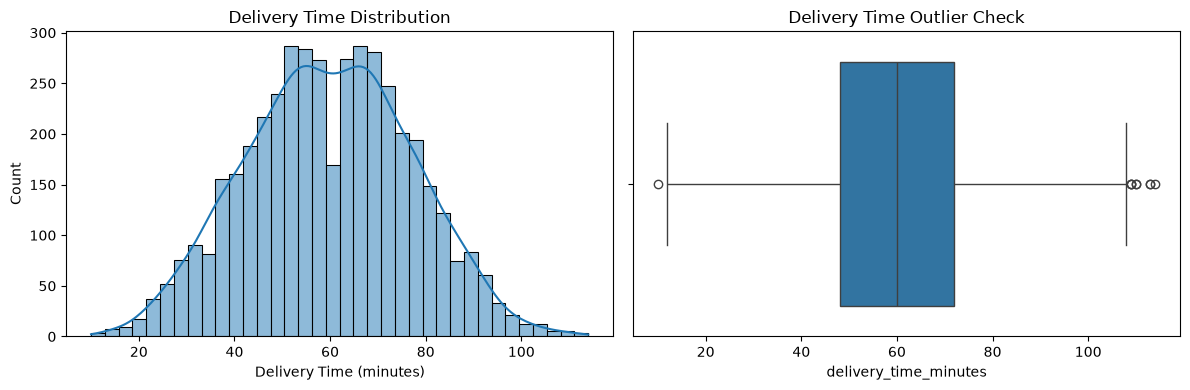

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

target = "delivery_time_minutes"

print(df[target].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df[target], kde=True, ax=axes[0])
axes[0].set_title("Delivery Time Distribution")
axes[0].set_xlabel("Delivery Time (minutes)")

sns.boxplot(x=df[target], ax=axes[1])
axes[1].set_title("Delivery Time Outlier Check")

plt.tight_layout()
plt.show()

,correlation
distance_km,0.675560
prep_time_minutes,0.544180
average_prep_time_minutes,0.518093
restaurant_rating,0.129399
driver_rating,0.011493
item_count,0.005152
experience_months,0.003400
delivery_fee,0.002366
discount,-0.002722
tax,-0.007282


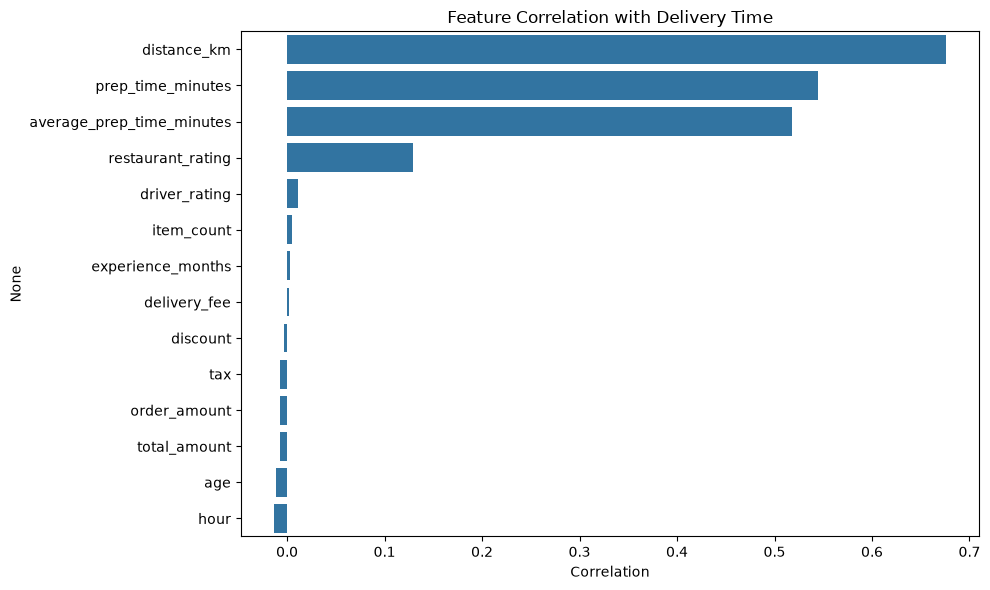

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

target = "delivery_time_minutes"

numeric_df = df.select_dtypes(include=np.number)

correlations = (
    numeric_df.corr()[target]
    .drop(target)
    .sort_values(ascending=False)
)

display(correlations.to_frame("correlation"))

plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index)
plt.title("Feature Correlation with Delivery Time")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

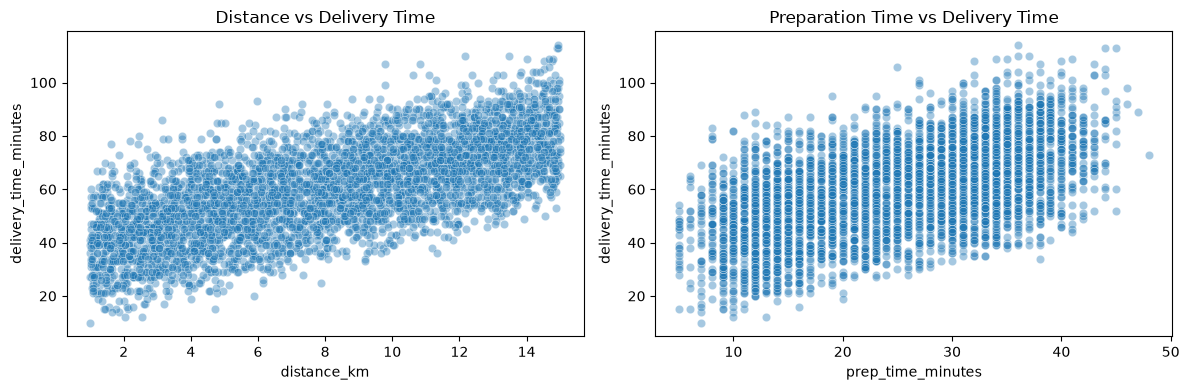

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(
    data=df, x="distance_km",
    y="delivery_time_minutes", alpha=0.4, ax=axes[0]
)
axes[0].set_title("Distance vs Delivery Time")

sns.scatterplot(
    data=df, x="prep_time_minutes",
    y="delivery_time_minutes", alpha=0.4, ax=axes[1]
)
axes[1].set_title("Preparation Time vs Delivery Time")

plt.tight_layout()
plt.show()

In [16]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
target = "delivery_time_minutes"

numeric_features = [
    "distance_km",
    "prep_time_minutes",
    "item_count",
    "order_amount"
]

categorical_features = [
    "weather",
    "traffic"
]

features = numeric_features + categorical_features

# Prepare modeling data
model_df = df[features + [target]].dropna(subset=[target]).copy()

X = model_df[features]
y = model_df[target]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessor defined successfully.")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Preprocessor defined successfully.
Training rows: 3528
Testing rows: 882


In [17]:
models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
predictions = {}
fitted_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    fitted_models[name] = pipeline
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Ridge Regression,3.232,4.114,0.944
1,Lasso Regression,3.240,4.124,0.943
2,Random Forest,3.600,4.562,0.931
3,Baseline,14.033,17.307,-0.000


In [18]:
cv_results = []

for name, pipeline in fitted_models.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV MAE": -scores["test_mae"].mean(),
        "CV RMSE": -scores["test_rmse"].mean(),
        "CV R2": scores["test_r2"].mean()
    })

cv_df = pd.DataFrame(cv_results).sort_values("CV RMSE")
display(cv_df.round(3))

,Model,CV MAE,CV RMSE,CV R2
1,Ridge Regression,3.241,4.055,0.945
2,Lasso Regression,3.257,4.075,0.944
3,Random Forest,3.706,4.658,0.927
0,Baseline,14.101,17.267,-0.002


,Feature,Importance
0,num__distance_km,0.4860
1,num__prep_time_minutes,0.3230
7,cat__traffic_High,0.1011
6,cat__weather_Rain,0.0402
3,num__order_amount,0.0126
8,cat__traffic_Low,0.0114
9,cat__traffic_Medium,0.0095
4,cat__weather_Clear,0.0086
2,num__item_count,0.0057
5,cat__weather_Cloudy,0.0018


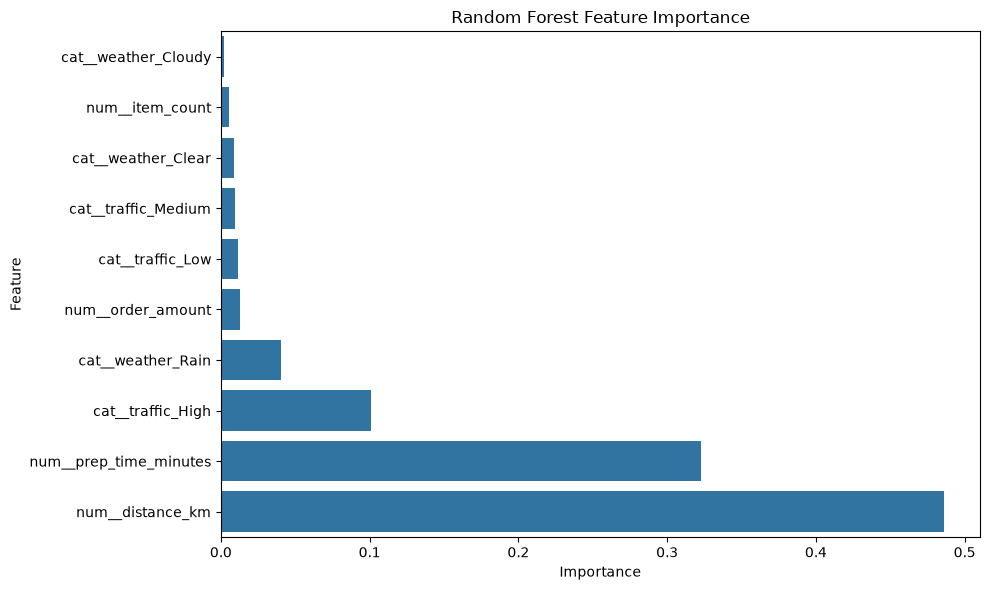

In [19]:
rf_pipeline = fitted_models["Random Forest"]

feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15).sort_values("Importance"),
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

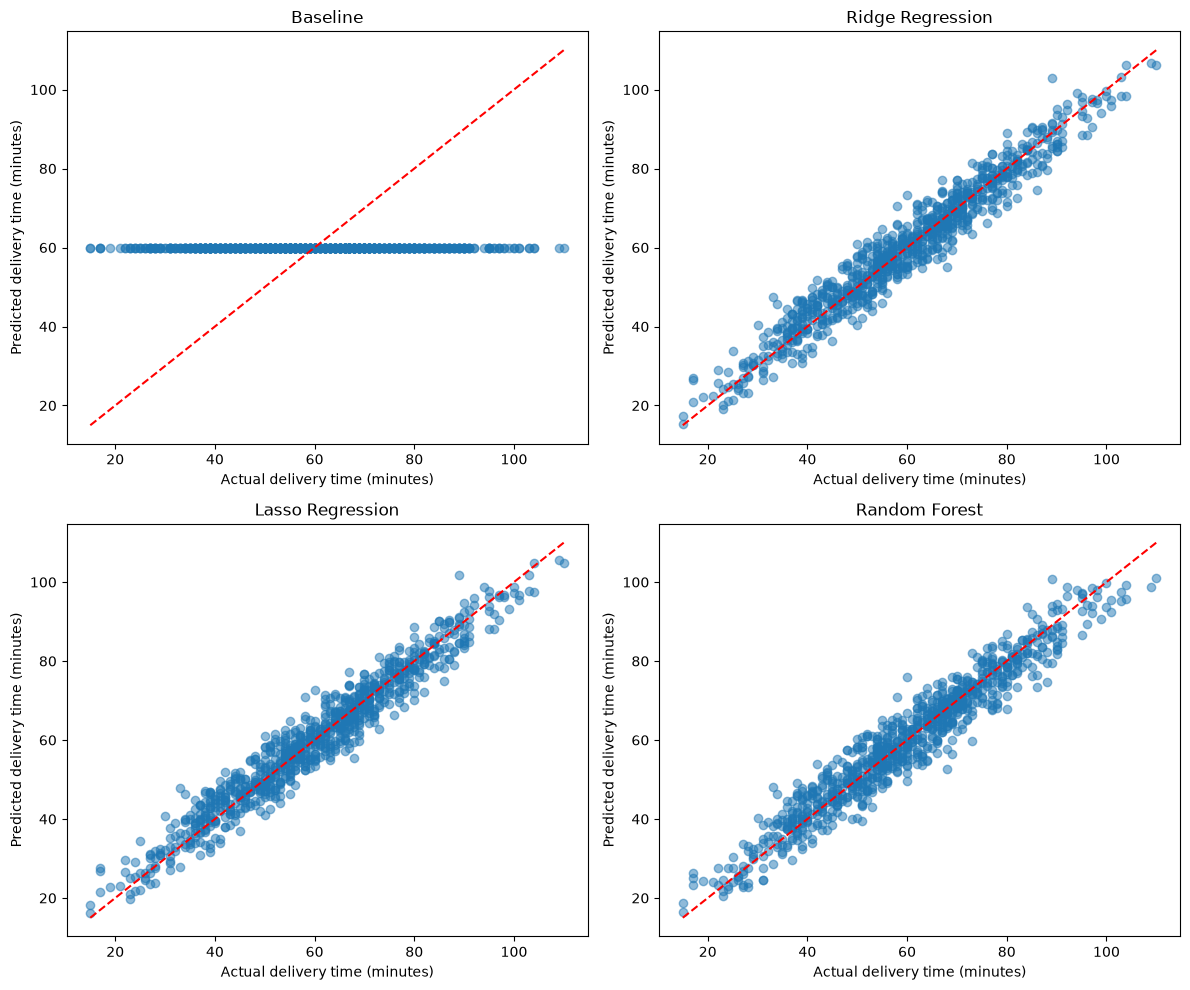

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):

    ax.scatter(y_test, y_pred, alpha=0.5)

    lower = min(y_test.min(), np.min(y_pred))
    upper = max(y_test.max(), np.max(y_pred))

    ax.plot([lower, upper], [lower, upper], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual delivery time (minutes)")
    ax.set_ylabel("Predicted delivery time (minutes)")

plt.tight_layout()
plt.show()

In [21]:
rf_pipeline = fitted_models["Random Forest"]

train_pred = rf_pipeline.predict(X_train)
test_pred = predictions["Random Forest"]

print("Training MAE:", round(mean_absolute_error(y_train, train_pred), 3))
print("Testing MAE:", round(mean_absolute_error(y_test, test_pred), 3))

print("Training R2:", round(r2_score(y_train, train_pred), 3))
print("Testing R2:", round(r2_score(y_test, test_pred), 3))

Training MAE: 1.84
Testing MAE: 3.6
Training R2: 0.981
Testing R2: 0.931


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get the trained Ridge pipeline
ridge_pipeline = fitted_models["Ridge Regression"]

# Get the transformed feature names
feature_names = (
    ridge_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Ridge coefficients
coefficients = ridge_pipeline.named_steps["model"].coef_

# Create a feature-importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance_df["Absolute_Importance"] = (
    importance_df["Coefficient"].abs()
)

importance_df = importance_df.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(importance_df.head(15).round(3))

,Feature,Coefficient,Absolute_Importance
0,num__distance_km,11.977,11.977
1,num__prep_time_minutes,9.738,9.738
7,cat__traffic_High,8.682,8.682
8,cat__traffic_Low,-7.419,7.419
6,cat__weather_Rain,6.839,6.839
4,cat__weather_Clear,-5.018,5.018
5,cat__weather_Cloudy,-1.821,1.821
9,cat__traffic_Medium,-1.263,1.263
2,num__item_count,0.151,0.151
3,num__order_amount,-0.110,0.110


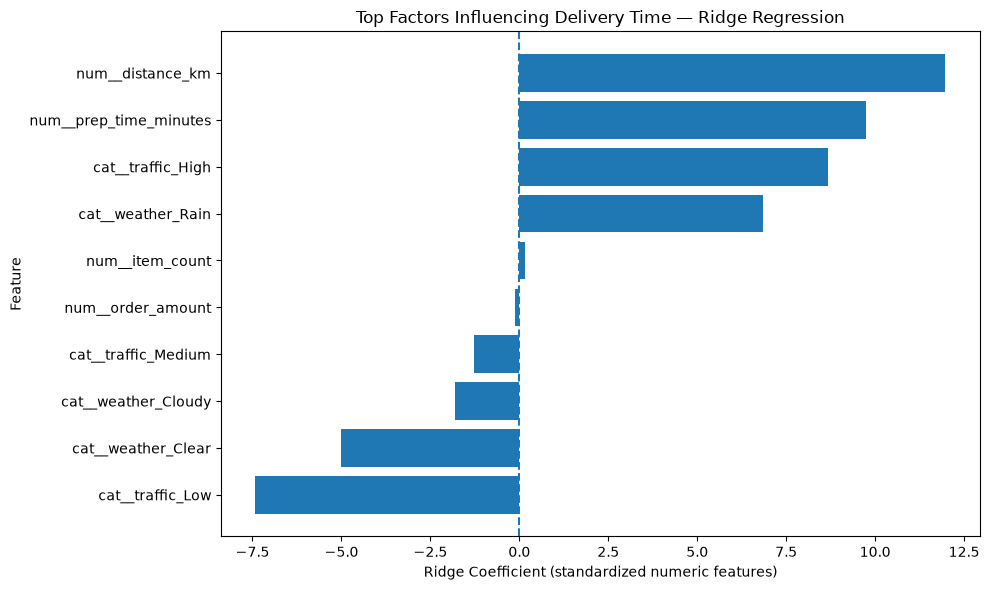

In [23]:
top_features = importance_df.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linestyle="--")
plt.title("Top Factors Influencing Delivery Time — Ridge Regression")
plt.xlabel("Ridge Coefficient (standardized numeric features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [24]:
# Create a residual analysis DataFrame
residual_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions["Ridge Regression"]
})

residual_df["Residual"] = (
    residual_df["Actual"] - residual_df["Predicted"]
)

residual_df["Absolute_Error"] = (
    residual_df["Residual"].abs()
)

display(residual_df.head(10).round(2))

print("Mean residual:", round(residual_df["Residual"].mean(), 3))
print("Mean absolute error:", round(residual_df["Absolute_Error"].mean(), 3))
print("Maximum absolute error:", round(residual_df["Absolute_Error"].max(), 3))

,Actual,Predicted,Residual,Absolute_Error
1413,50,48.61,1.39,1.39
3352,66,70.58,-4.58,4.58
3970,68,68.49,-0.49,0.49
3629,34,38.78,-4.78,4.78
144,63,61.77,1.23,1.23
1746,72,76.39,-4.39,4.39
2154,80,73.88,6.12,6.12
4324,66,62.50,3.50,3.50
4407,83,86.33,-3.33,3.33
2578,60,63.63,-3.63,3.63


Mean residual: -0.276
Mean absolute error: 3.232
Maximum absolute error: 14.561
